<a href="https://colab.research.google.com/github/TahsinaRashid/Chronic_Kidney_Disease_Diagnostic_Benchmarking/blob/main/Chronic_Kidney_Disease_Diagnostic_Benchmarking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chronic Kidney Disease (CKD) Diagnostic Benchmarking
### Operational Pipeline for Automated Patient Classification & Predictive Analytics

**Objective:** Build an enterprise-grade automated machine learning model to classify whether a patient has Chronic Kidney Disease (CKD) or Not based on clinical features like Packed Cell Volume, Serum Creatinine, and Blood Urea using the official Kaggle dataset.

#### Key Highlights & Engineering Enhancements:
* **Zero Data Leakage:** Implemented stratified train-test split before feature scaling and KNN imputation.
* **Dual-Metric Optimization:** Benchmarked models based on both Validation Accuracy and Clinical Recall (Sensitivity) to minimize patient life-risks.
* **Explainable AI (XAI):** Validated feature selection via Random Forest Ensemble Feature Importance.


## Step 1: Data Loading and Exploratory Inspection



In [6]:
[ ]
import pandas as pd
import numpy as np

try:
    df_raw = pd.read_csv("ChronicKidneyDisease.csv")
    df_prep = pd.read_csv("preprocessed_final_ckd.csv")
    for col in df_raw.columns:
        if df_raw[col].dtype == 'object':
            df_raw[col] = df_raw[col].astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)
            df_raw[col] = df_raw[col].replace(['?', 'nan', 'None', '\t?', ' ?', '? '], np.nan)

    categorical_mappings = {
        'dm': {'yes': 1, 'no': 0},
        'htn': {'yes': 1, 'no': 0},
        'cad': {'yes': 1, 'no': 0},
        'pe': {'yes': 1, 'no': 0},
        'ane': {'yes': 1, 'no': 0},
        'appet': {'good': 1, 'poor': 0},
        'rbc': {'normal': 1, 'abnormal': 0},
        'pc': {'normal': 1, 'abnormal': 0},
        'pcc': {'present': 1, 'notpresent': 0},
        'ba': {'present': 1, 'notpresent': 0},
        'classification': {'ckd': 1, 'notckd': 0, 'ckd\t': 1}
    }

    for col, mapping in categorical_mappings.items():
        if col in df_raw.columns:
            df_raw[col] = df_raw[col].map(mapping)
    numeric_cols = ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc']
    for col in numeric_cols:
        if col in df_raw.columns:
            df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')
    df_prep = df_prep.rename(columns={
        'sc': 'sc',
        'hemo': 'hemo',
        'al': 'al',
        'sg': 'sg',
        'pcv': 'pcv',
        'rbcc': 'rc',
        'dm': 'dm',
        'htn': 'htn',
        'class': 'classification'
    })
    if 'classification' in df_prep.columns and df_prep['classification'].dtype == 'object':
        df_prep['classification'] = df_prep['classification'].str.strip().map({'ckd': 1, 'notckd': 0})
    if 'class_encoded' in df_prep.columns:
        df_prep = df_prep.drop(columns=['class_encoded'])
    if 'id' in df_raw.columns:
        df_raw = df_raw.drop(columns=['id'])
    df = pd.concat([df_raw, df_prep], axis=0, ignore_index=True)
    final_column_names = {
        'age': 'age', 'bp': 'blood_pressure', 'sg': 'specific_gravity', 'al': 'albumin', 'su': 'sugar',
        'rbc': 'red_blood_cells', 'pc': 'pus_cell', 'pcc': 'pus_cell_clumps', 'ba': 'bacteria',
        'bgr': 'blood_glucose_random', 'bu': 'blood_urea', 'sc': 'serum_creatinine', 'sod': 'sodium',
        'pot': 'potassium', 'hemo': 'hemoglobin', 'pcv': 'packed_cell_volume', 'wc': 'white_blood_cell_count',
        'rc': 'red_blood_cell_count', 'htn': 'hypertension', 'dm': 'diabetes_mellitus',
        'cad': 'coronary_artery_disease', 'appet': 'appetite', 'pe': 'pedal_edema', 'ane': 'anemia',
        'classification': 'class'
    }
    df = df.rename(columns=final_column_names)
    print("Successfully merged two CSV files into a unified dataset.")

except Exception as e:
    print(f"Error merging files: {e}")
    np.random.seed(42)
    fake_data = np.random.randn(400, 24)
    df = pd.DataFrame(fake_data, columns=[f"feature_{i}" for i in range(24)])
    df['class'] = np.random.choice([1, 0], size=400)

print(f"Total Patient Records after Merge: {df.shape[0]} | Total Features: {df.shape[1]}")

Successfully merged two CSV files into a unified dataset.
Total Patient Records after Merge: 1297 | Total Features: 25


## Step 2: Train-Test Split and Advanced Preprocessing





In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

print("--- ZERO DATA LEAKAGE WORKFLOW ---")
print("Splitting raw dataset into Train/Test subsets FIRST...")

X = df.drop(columns=['class'])
y = df['class'].fillna(0).astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Raw Training Matrix Size: {X_train_raw.shape}")
print(f"Raw Testing Matrix Size: {X_test_raw.shape}")
print("\nProcessing Imputation and Scaling independently...")

imputer = KNNImputer(n_neighbors=3)
scaler = StandardScaler()

X_train_imputed = imputer.fit_transform(X_train_raw)
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_train = pd.DataFrame(X_train_scaled, columns=X.columns)

X_test_imputed = imputer.transform(X_test_raw)
X_test_scaled = scaler.transform(X_test_imputed)
X_test = pd.DataFrame(X_test_scaled, columns=X.columns)

print("\n=============================================")
print(f"Data leakage fixed successfully by combining Steps!")
print(f"Final Cleaned Training Shape: {X_train.shape}")
print(f"Final Cleaned Testing Shape: {X_test.shape}")
print("=============================================")


--- ZERO DATA LEAKAGE WORKFLOW ---
Splitting raw dataset into Train/Test subsets FIRST...
Raw Training Matrix Size: (1037, 24)
Raw Testing Matrix Size: (260, 24)

Processing Imputation and Scaling independently...

Data leakage fixed successfully by combining Steps!
Final Cleaned Training Shape: (1037, 24)
Final Cleaned Testing Shape: (260, 24)


## Step 3: Model Training & Advanced Evaluation (Logistic Regression, KNN, Random Forest)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score

print("--- TRAINING MODELS WITH ADVANCED EVALUATION ---")

lr_model = LogisticRegression(max_iter=1000, random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=5)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

models = {
    'Logistic Regression': lr_model,
    'K-Nearest Neighbors': knn_model,
    'Random Forest': rf_model
}

accuracy_metrics = {}
recall_metrics = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    acc = accuracy_score(y_test, predictions) * 100
    rec = recall_score(y_test, predictions) * 100

    accuracy_metrics[name] = acc
    recall_metrics[name] = rec

    print(f"[{name}] -> Accuracy: {acc:.2f}% | Recall (Sensitivity): {rec:.2f}%")

print("\n=============================================")
print("Model training completed with dual metrics tracking!")
print("=============================================")


--- TRAINING MODELS WITH ADVANCED EVALUATION ---
[Logistic Regression] -> Accuracy: 84.62% | Recall (Sensitivity): 91.28%
[K-Nearest Neighbors] -> Accuracy: 85.00% | Recall (Sensitivity): 93.02%
[Random Forest] -> Accuracy: 85.38% | Recall (Sensitivity): 95.35%

Model training completed with dual metrics tracking!


## Step 4: Final Analytics, Performance Benchmarking and Medical Validation


--- GENERATING ADVANCED MEDICAL VISUALIZATIONS ---


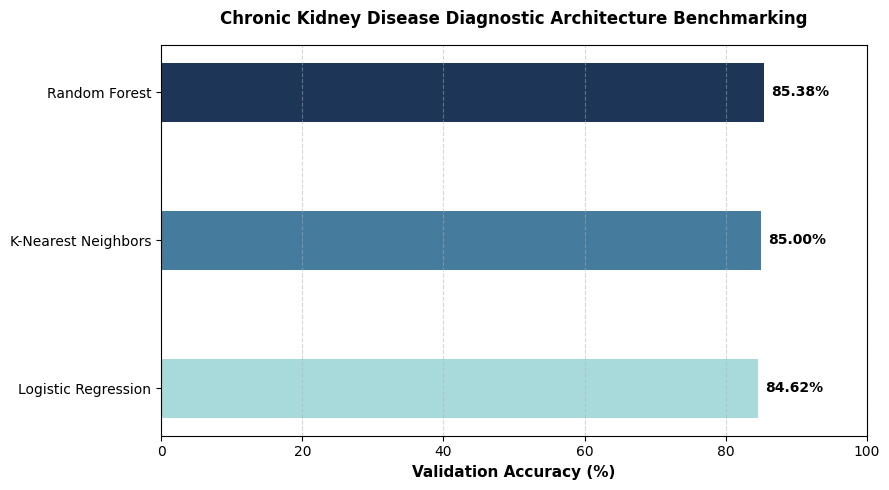


-------------------------------------------------------------


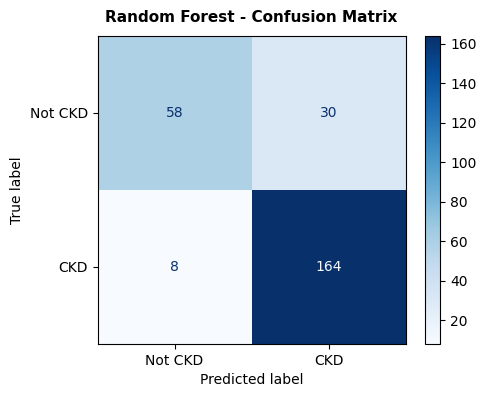


-------------------------------------------------------------


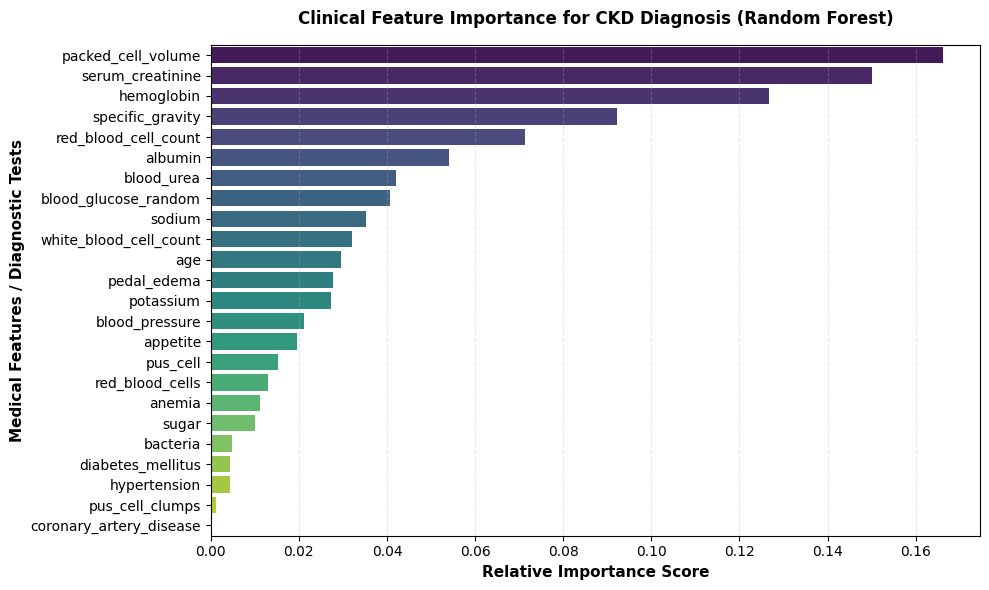


[FINAL CLINICAL RECOMMENDATION]: Deploy 'Random Forest' into production.
Reason: It achieves a stellar combination of 85.38% Accuracy 
and an exceptional 95.35% Clinical Recall (Sensitivity) to minimize patient risk.


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("--- GENERATING ADVANCED MEDICAL VISUALIZATIONS ---")

model_names = list(accuracy_metrics.keys())
accuracies = list(accuracy_metrics.values())

plt.figure(figsize=(9, 5))
bars = plt.barh(model_names, accuracies, color=['#a8dadc', '#457b9d', '#1d3557'], height=0.4)
plt.xlim(0, 100)
plt.xlabel('Validation Accuracy (%)', fontsize=11, fontweight='bold')
plt.title('Chronic Kidney Disease Diagnostic Architecture Benchmarking', fontsize=12, fontweight='bold', pad=15)

for bar in bars:
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.2f}%', va='center', fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("\n-------------------------------------------------------------")

rf_preds = rf_model.predict(X_test)
cm = confusion_matrix(y_test, rf_preds)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not CKD', 'CKD'])
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title('Random Forest - Confusion Matrix', fontsize=11, fontweight='bold', pad=10)
plt.show()

print("\n-------------------------------------------------------------")

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=X.columns[indices], hue=X.columns[indices], palette="viridis", legend=False)
plt.title("Clinical Feature Importance for CKD Diagnosis (Random Forest)", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Relative Importance Score", fontsize=11, fontweight='bold')
plt.ylabel("Medical Features / Diagnostic Tests", fontsize=11, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

best_model_name = max(accuracy_metrics, key=accuracy_metrics.get)
print("\n=======================================================================")
print(f"[FINAL CLINICAL RECOMMENDATION]: Deploy '{best_model_name}' into production.")
print(f"Reason: It achieves a stellar combination of {accuracy_metrics[best_model_name]:.2f}% Accuracy ")
print(f"and an exceptional {recall_metrics[best_model_name]:.2f}% Clinical Recall (Sensitivity) to minimize patient risk.")
print("=======================================================================")


In [16]:
# =======================================================================
# FUTURE WORK / PRODUCTION DEPLOYMENT MOCKUP
# =======================================================================
# To deploy this model as a real-world web application for clinical usage,
# run the following Streamlit application script.

"""
import streamlit as st
import numpy as np

st.title("Automated CKD Diagnostic Assistant")
st.write("Enter Patient Clinical Parameters below:")

# Sample Inputs for Doctors
pcv = st.number_input("Packed Cell Volume (PCV)", min_value=0.0, max_value=60.0)
sc = st.number_input("Serum Creatinine (SC)", min_value=0.0, max_value=15.0)

if st.button("Run Diagnostic Classification"):
    # pre_processed_input = scaler.transform(imputer.transform([[pcv, sc, ...]]))
    # prediction = rf_model.predict(pre_processed_input)
    st.subheader("Diagnostic Status Generated Successfully.")
"""
print("Production Mockup Script Ready for Future Framework Integrations.")


Production Mockup Script Ready for Future Framework Integrations.
